In [5]:
import re
import numpy as np

def parse_iqae_ceiling_file(filepath):
    """
    Parse an IQAE ceiling-mode frontier data export file.
    Extracts the first 4 columns: epsilon, p_star, s_hat, n_shots

    Returns:
        epsilon  : np.ndarray
        p_star   : np.ndarray
        s_hat    : np.ndarray
        n_shots  : np.ndarray (int)
    """
    epsilons = []
    p_stars  = []
    s_hats   = []
    n_shots  = []

    with open(filepath, "r") as f:
        lines = f.readlines()

    in_data_section = False

    for line in lines:
        line = line.strip()

        # ── Detect start of data section ──────────────────────────────────────
        if line.startswith("epsilon | p_star"):
            in_data_section = True
            continue  # skip the header row

        # ── Skip separator line ───────────────────────────────────────────────
        if in_data_section and set(line) <= set("-"):
            continue

        # ── Parse data rows ───────────────────────────────────────────────────
        if in_data_section and "|" in line:
            parts = [p.strip() for p in line.split("|")]
            epsilons.append(float(parts[0]))
            p_stars.append(float(parts[1]))
            s_hats.append(float(parts[2]))
            n_shots.append(int(parts[3]))

    return (
        np.array(epsilons),
        np.array(p_stars),
        np.array(s_hats),
        np.array(n_shots),
    )


# ── Usage ─────────────────────────────────────────────────────────────────────
ALPHA = 0.05
epsilon, p_star, s_hat, n_shots = parse_iqae_ceiling_file("ceiling_sweep_trainsition.txt")

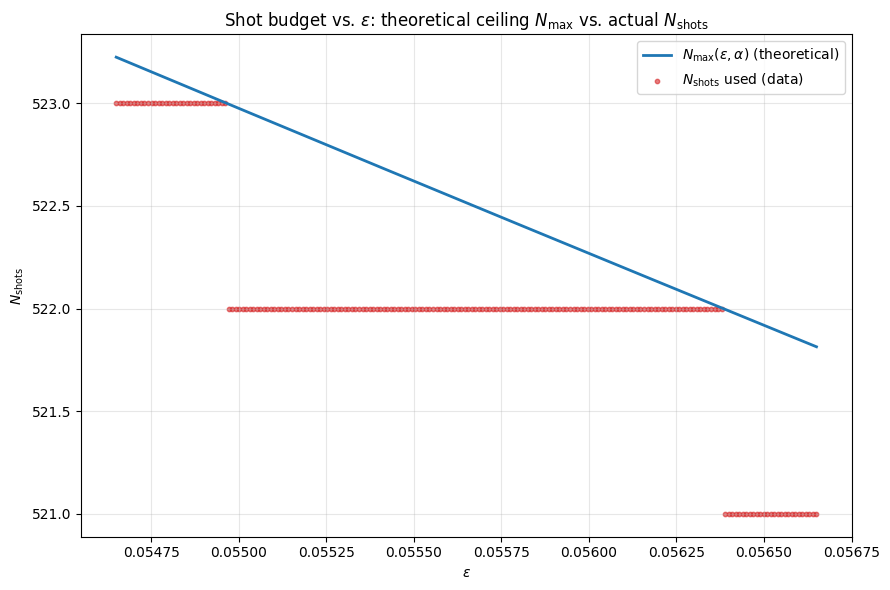

In [6]:
import matplotlib.pyplot as plt

# ── Function ──────────────────────────────────────────────────────────────────
def N_max(epsilon, alpha):
    return (32 / (1 - 2 * np.sin(np.pi / 14)) ** 2) \
           * np.log((2 / alpha) * np.log2(np.pi / (4 * epsilon)))

eps_curve = np.linspace(epsilon.min(), epsilon.max(), 2000)
nmax_curve = N_max(eps_curve, ALPHA)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(eps_curve, nmax_curve, color="#1f77b4", linewidth=2,
        label=r"$N_{\max}(\varepsilon, \alpha)$ (theoretical)")

ax.scatter(epsilon, n_shots, color="#d62728", s=10, alpha=0.6,
           label=r"$N_{\rm shots}$ used (data)")

ax.set_xlabel(r"$\varepsilon$")
ax.set_ylabel(r"$N_{\rm shots}$")
ax.set_title(r"Shot budget vs. $\varepsilon$: theoretical ceiling $N_{\max}$ vs. actual $N_{\rm shots}$")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

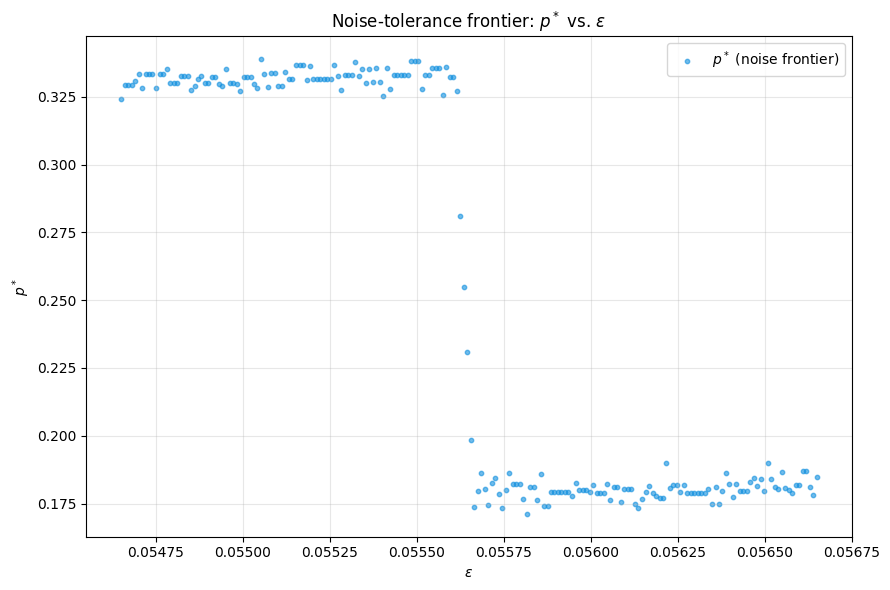

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(epsilon, p_star, color="#1190df", s=10, alpha=0.6,
           label=r"$p^*$ (noise frontier)")

ax.set_xlabel(r"$\varepsilon$")
ax.set_ylabel(r"$p^*$")
ax.set_title(r"Noise-tolerance frontier: $p^*$ vs. $\varepsilon$")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES — imports, problem definition, noise model, N_max
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
from joblib import Parallel, delayed

from qiskit.circuit import QuantumCircuit
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem

print("All imports OK ✅")

# ── Fixed experiment parameters ────────────────────────────────────────────────
p_true = 0.2
ALPHA  = 0.05
N_JOBS = 18


# ── Bernoulli amplitude estimation problem ─────────────────────────────────────
class BernoulliA(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)


class BernoulliQ(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k


problem = EstimationProblem(
    state_preparation=BernoulliA(p_true),
    grover_operator=BernoulliQ(p_true),
    objective_qubits=[0],
)
print("Problem defined ✅")


# ── Noise model builder ────────────────────────────────────────────────────────
SINGLE_QUBIT_GATES = [
    'id', 'x', 'y', 'z', 'h', 's', 'sdg', 't', 'tdg',
    'sx', 'sxdg', 'rx', 'ry', 'rz',
    'u', 'u1', 'u2', 'u3', 'p'
]

# Physical ceiling for 1-qubit depolarizing_error: λ ∈ [0, 1] is the
# physically meaningful range (λ=1 is full depolarization).
MAX_PHYSICAL_DEPOL = 1.0

def build_noisy_sampler(p_depol, n_shots):
    if p_depol > 0.0:
        p_1q = min(p_depol, MAX_PHYSICAL_DEPOL)
        error_1q = depolarizing_error(p_1q, 1)

        noise_model = NoiseModel()
        noise_model.add_all_qubit_quantum_error(error_1q, SINGLE_QUBIT_GATES)

        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": n_shots}
        )
    else:
        sampler = AerSampler(run_options={"shots": n_shots})
    return sampler


# ── Ceiling shot budget N_max(eps, alpha) ─────────────────────────────────────
def N_max(epsilon, alpha):
    raw = (32 / (1 - 2 * np.sin(np.pi / 14)) ** 2) \
          * np.log((2 / alpha) * np.log2(np.pi / (4 * epsilon)))
    return int(np.floor(raw))

print("Prerequisites loaded ✅")

All imports OK ✅
Problem defined ✅
Prerequisites loaded ✅


In [9]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL A 
# ══════════════════════════════════════════════════════════════════════════════
def _safe_float(x):
    return float(x) if x is not None else None

def _safe_list(x):
    return list(x) if x is not None else None

def _safe_list_of_lists(x):
    return [list(item) for item in x] if x is not None else None


def single_diag_run_full(eps, p_noise, n_shots):
    """
    One IQAE run at (eps, p_noise) with shot budget n_shots.
    Captures the full IterativeAmplitudeEstimationResult, excluding
    circuit_results (raw statevector/counts — not needed here).
    Each field is converted defensively so a single None/missing field
    doesn't discard the whole run.
    """
    try:
        sampler = build_noisy_sampler(p_noise, n_shots)
        iae     = IterativeAmplitudeEstimation(
            epsilon_target = eps,
            alpha          = ALPHA,
            sampler        = sampler,
        )
        result = iae.estimate(problem)

        powers   = list(result.powers) if result.powers is not None else []
        K_values = [2 * k + 1 for k in powers]

        estimate = _safe_float(result.estimation_processed)
        success  = int(estimate is not None and abs(estimate - p_true) <= eps)

        return {
            "success"                      : success,
            "powers"                       : powers,
            "K_values"                     : K_values,
            "T_eps"                        : len(powers),
            "max_K"                        : max(K_values) if K_values else None,
            "sum_K"                        : sum(K_values) if K_values else None,

            # amplitude-domain results
            "estimation"                   : estimate,
            "signed_error"                 : (estimate - p_true) if estimate is not None else None,
            "confidence_interval"          : _safe_list(result.confidence_interval),
            "confidence_interval_processed": _safe_list(result.confidence_interval_processed),
            "estimate_intervals"           : _safe_list_of_lists(result.estimate_intervals),

            # angle-domain results
            "theta_intervals"              : _safe_list_of_lists(result.theta_intervals),

            # schedule / information mechanics
            "ratios"                       : _safe_list(result.ratios),
            "num_oracle_queries"           : int(result.num_oracle_queries) if result.num_oracle_queries is not None else None,

            # precision bookkeeping
            "epsilon_target"               : _safe_float(result.epsilon_target),
            "epsilon_estimated"            : _safe_float(result.epsilon_estimated),
            "epsilon_estimated_processed"  : _safe_float(result.epsilon_estimated_processed),
            "alpha_echo"                   : _safe_float(result.alpha),

            # sampling bookkeeping
            "shots"                        : result.shots,
            "n_shots_requested"            : n_shots,

            "error_message"                : None,
        }

    except Exception as e:
        err_str = f"{type(e).__name__}: {e}"
        print(f"[WARN] single_diag_run_full failed: {err_str}")
        return {
            "success": 0, "powers": [], "K_values": [], "T_eps": 0,
            "max_K": None, "sum_K": None,
            "estimation": None, "signed_error": None,
            "confidence_interval": None, "confidence_interval_processed": None,
            "estimate_intervals": None, "theta_intervals": None,
            "ratios": None, "num_oracle_queries": None,
            "epsilon_target": eps, "epsilon_estimated": None,
            "epsilon_estimated_processed": None, "alpha_echo": ALPHA,
            "shots": None, "n_shots_requested": n_shots,
            "error_message": err_str,
        }

In [10]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL B
# ══════════════════════════════════════════════════════════════════════════════

from collections import Counter
from joblib import Parallel, delayed
import numpy as np

N_DIAG = 500   # runs per point

diag_results = []

for eps, p_star_val in zip(epsilon, p_star):
    n_shots_diag = int(N_max(eps, ALPHA))   # ← only difference from fixed-shots version

    print(f"\n{'─'*60}")
    print(f"ε={eps:.6f} | p*={p_star_val:.6f} | N_shots={n_shots_diag} "
          f"| running {N_DIAG} runs ...")

    runs = Parallel(n_jobs=N_JOBS)(
        delayed(single_diag_run_full)(eps, p_star_val, n_shots_diag)
        for _ in range(N_DIAG)
    )

    # ── Live per-run schedule output ─────────────────────────────────────────
    for i, run in enumerate(runs):
        if run["error_message"] is not None:
            print(f"  run {i+1:>3} | ERROR: {run['error_message']}")
            continue

        status  = "✅" if run["success"] else "❌"
        err_str = f"{run['signed_error']:.6f}" if run["signed_error"] is not None else "N/A"
        print(f"  run {i+1:>3} | {status} | T={run['T_eps']:>2} | "
              f"K_values={run['K_values']} | signed_error={err_str}")

    # ── Aggregate ──────────────────────────────────────────────────────────
    valid_runs   = [r for r in runs if r["T_eps"] > 0]
    success_rate = np.mean([r["success"] for r in runs])

    T_values    = [r["T_eps"]  for r in valid_runs]
    maxK_values = [r["max_K"]  for r in valid_runs]
    sumK_values = [r["sum_K"]  for r in valid_runs]
    err_values  = [r["signed_error"] for r in valid_runs if r["signed_error"] is not None]

    schedule_counts = Counter(tuple(r["K_values"]) for r in valid_runs)
    most_common_schedule, most_common_count = (
        schedule_counts.most_common(1)[0] if schedule_counts else ((), 0)
    )

    diag_results.append({
        "epsilon"              : eps,
        "p_star"               : p_star_val,
        "n_shots"              : n_shots_diag,
        "success_rate"         : success_rate,
        "T_mean"               : float(np.mean(T_values)) if T_values else None,
        "T_std"                : float(np.std(T_values))  if T_values else None,
        "max_K_mean"           : float(np.mean(maxK_values)) if maxK_values else None,
        "sum_K_mean"           : float(np.mean(sumK_values)) if sumK_values else None,
        "mean_signed_error"    : float(np.mean(err_values)) if err_values else None,
        "most_common_schedule" : list(most_common_schedule),
        "most_common_count"    : most_common_count,
        "n_valid_runs"         : len(valid_runs),
        "raw_runs"             : runs,
    })

    print(f"  → success_rate={success_rate:.3f} | "
          f"most_common_schedule={list(most_common_schedule)} "
          f"({most_common_count}/{len(valid_runs)})")

print("\n✅ Full diagnostic sweep complete.")


────────────────────────────────────────────────────────────
ε=0.054650 | p*=0.324219 | N_shots=523 | running 500 runs ...
  run   1 | ❌ | T= 3 | K_values=[1, 1, 9] | signed_error=0.111368
  run   2 | ✅ | T= 3 | K_values=[1, 1, 7] | signed_error=0.038102
  run   3 | ❌ | T= 3 | K_values=[1, 1, 9] | signed_error=0.109061
  run   4 | ❌ | T= 3 | K_values=[1, 1, 9] | signed_error=0.116298
  run   5 | ✅ | T= 3 | K_values=[1, 1, 7] | signed_error=0.034633
  run   6 | ❌ | T= 3 | K_values=[1, 1, 9] | signed_error=0.110742
  run   7 | ❌ | T= 3 | K_values=[1, 1, 9] | signed_error=0.112405
  run   8 | ❌ | T= 3 | K_values=[1, 1, 9] | signed_error=0.113231
  run   9 | ✅ | T= 3 | K_values=[1, 1, 7] | signed_error=0.039021
  run  10 | ✅ | T= 3 | K_values=[1, 1, 7] | signed_error=0.041422
  run  11 | ❌ | T= 3 | K_values=[1, 1, 9] | signed_error=0.114463
  run  12 | ❌ | T= 3 | K_values=[1, 1, 9] | signed_error=0.112612
  run  13 | ✅ | T= 3 | K_values=[1, 1, 7] | signed_error=0.039021
  run  14 | ✅ | T=

In [11]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL C
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import pickle

eps_out          = []
p_star_out       = []
T_out            = []
K_values_out     = []
ratios_out       = []
success_out      = []   # NEW: needed to filter T by success in Cell D
n_shots_diag_out = []   # NEW: shot budget varies per epsilon in ceiling mode, so track per-run

for point in diag_results:
    eps_val         = point["epsilon"]
    p_star_val      = point["p_star"]
    n_shots_diag_val = point["n_shots"]   # N_max(eps, ALPHA) for this epsilon

    for run in point["raw_runs"]:
        eps_out.append(eps_val)
        p_star_out.append(p_star_val)
        T_out.append(run["T_eps"])
        K_values_out.append(run["K_values"])   # variable-length list, kept as-is
        ratios_out.append(run["ratios"])       # variable-length list, kept as-is
        success_out.append(bool(run["success"]))
        n_shots_diag_out.append(n_shots_diag_val)

eps_arr          = np.array(eps_out)
p_star_arr       = np.array(p_star_out)
T_arr            = np.array(T_out)
K_values_arr     = np.array(K_values_out, dtype=object)   # ragged array of lists
ratios_arr       = np.array(ratios_out, dtype=object)     # ragged array of lists
success_arr      = np.array(success_out, dtype=bool)
n_shots_diag_arr = np.array(n_shots_diag_out, dtype=int)

print(f"Exported {len(eps_arr)} run records "
      f"across {len(diag_results)} epsilon points.")

# ── Save to disk ────────────────────────────────────────────────────────────
np.savez(
    "ceilingsweep_transition.npz",
    epsilon=eps_arr,
    p_star=p_star_arr,
    T=T_arr,
    K_values=K_values_arr,
    ratios=ratios_arr,
    success=success_arr,
    n_shots_diag=n_shots_diag_arr,
    allow_pickle=True,
)

print("✅ Saved")

Exported 100000 run records across 200 epsilon points.
✅ Saved


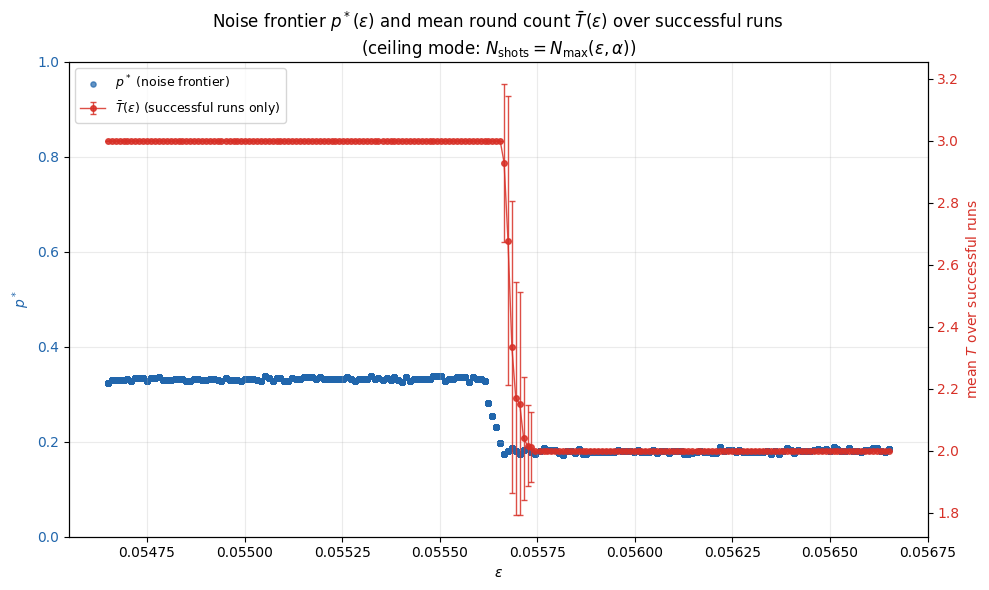

In [13]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL D — Plot: epsilon vs p_star, and mean T over SUCCESSFUL runs (dual y-axis)
# ══════════════════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import numpy as np

data = np.load("ceilingsweep_transition.npz", allow_pickle=True)
eps_arr          = data["epsilon"]
p_star_arr       = data["p_star"]
T_arr            = data["T"]
K_values_arr     = data["K_values"]
ratios_arr       = data["ratios"]
success_arr      = data["success"]
n_shots_diag_arr = data["n_shots_diag"]

# ── Per-point values (one per epsilon, from diag_results) ────────────────────
eps_points = eps_arr
p_star_pts = p_star_arr

# ── Aggregate T over successful runs only, per unique epsilon ───────────────
unique_eps = np.unique(eps_arr)
eps_agg     = []
T_succ_mean = []
T_succ_std  = []
n_succ_arr  = []

for eps_val in unique_eps:
    mask = (eps_arr == eps_val) & success_arr
    if np.any(mask):
        eps_agg.append(eps_val)
        T_succ_mean.append(T_arr[mask].mean())
        T_succ_std.append(T_arr[mask].std())
        n_succ_arr.append(mask.sum())
    else:
        print(f"⚠ no successful runs at ε={eps_val:.6f}, omitted from T plot")

eps_agg     = np.array(eps_agg)
T_succ_mean = np.array(T_succ_mean)
T_succ_std  = np.array(T_succ_std)

fig, ax1 = plt.subplots(figsize=(10, 6))

# ── Left axis: p_star ─────────────────────────────────────────────────────────
color_p = "#2166ac"
ax1.scatter(eps_points, p_star_pts, color=color_p, s=14, alpha=0.7,
            label=r"$p^*$ (noise frontier)")
ax1.set_xlabel(r"$\varepsilon$")
ax1.set_ylabel(r"$p^*$", color=color_p)
ax1.tick_params(axis="y", labelcolor=color_p)
ax1.set_ylim(0, 1)

# ── Right axis: mean T over successful runs, per epsilon ────────────────────
ax2 = ax1.twinx()
color_T = "#d73027"
ax2.errorbar(eps_agg, T_succ_mean, yerr=T_succ_std, fmt="o-",
             color=color_T, markersize=4, linewidth=1, capsize=2, alpha=0.85,
             label=r"$\bar{T}(\varepsilon)$ (successful runs only)")
ax2.set_ylabel(r"mean $T$ over successful runs", color=color_T)
ax2.tick_params(axis="y", labelcolor=color_T)

# n_shots is per-epsilon here (N_max(eps, alpha)), not a single scalar,
# so the title describes the rule rather than quoting one number
ax1.set_title(
    r"Noise frontier $p^*(\varepsilon)$ and mean round count "
    r"$\bar{T}(\varepsilon)$ over successful runs"
    "\n"
    r"(ceiling mode: $N_{\mathrm{shots}} = N_{\max}(\varepsilon, \alpha)$)"
)
ax1.grid(True, alpha=0.25)

# ── Combined legend ───────────────────────────────────────────────────────────
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()

Dominant cliff:
  BEFORE: ε=0.055615  p*=0.327190
  AFTER:  ε=0.055625  p*=0.281179
   idx           ε        p*       Δp*  T_dist                                   SR  zone
  ────  ──────────  ────────  ────────  ───────────────────────────────────  ──────  ───────────────
    91    0.055565    0.3356   +0.0000  T=2:  1  T=3:499                      0.496  pre-cliff ⚡MIXED
    92    0.055575    0.3256   -0.0100  T=2:  4  T=3:496                      0.546  pre-cliff ⚡MIXED
    93    0.055585    0.3361   +0.0105  T=2: 16  T=3:484                      0.480  pre-cliff ⚡MIXED
    94    0.055595    0.3324   -0.0037  T=2: 52  T=3:448                      0.526  pre-cliff ⚡MIXED
    95    0.055605    0.3322   -0.0002  T=2:149  T=3:351                      0.510  pre-cliff ⚡MIXED
    96    0.055615    0.3272   -0.0050  T=2:235  T=3:265                      0.530  ◀ BEFORE ⚡MIXED
    97    0.055625    0.2812   -0.0460  T=2:237  T=3:263                      0.526  AFTER ▶ ⚡MIXED
    98    0.05

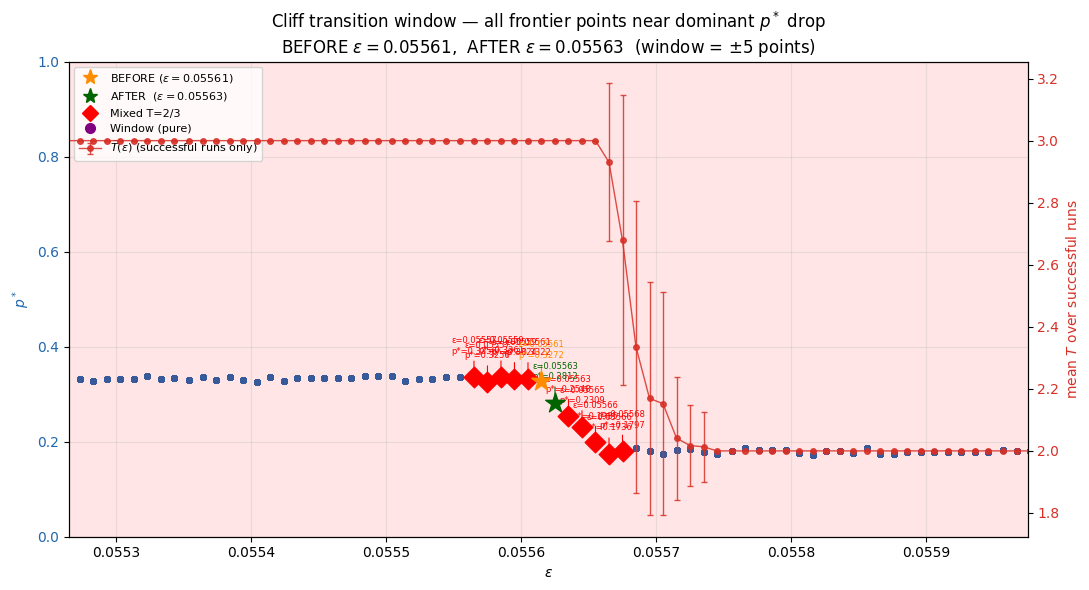

In [18]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL E (v3) — Load from .npz directly, inspect cliff transition window
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from matplotlib.lines import Line2D


# ── Reconstruct sorted unique frontier ───────────────────────────────────────
unique_eps_frontier, first_occ = np.unique(eps_arr, return_index=True)
p_star_frontier                = p_star_arr[first_occ]

sort_idx            = np.argsort(unique_eps_frontier)
eps_front_sorted    = unique_eps_frontier[sort_idx]
p_star_front_sorted = p_star_frontier[sort_idx]

# ── Rebuild T̄ aggregation for the plot ───────────────────────────────────────
eps_agg     = []
T_succ_mean = []
T_succ_std  = []

for eps_val in unique_eps_frontier:
    mask = (eps_arr == eps_val) & success_arr
    if np.any(mask):
        eps_agg.append(eps_val)
        T_succ_mean.append(T_arr[mask].mean())
        T_succ_std.append(T_arr[mask].std())

eps_agg     = np.array(eps_agg)
T_succ_mean = np.array(T_succ_mean)
T_succ_std  = np.array(T_succ_std)

# ── Find dominant cliff ───────────────────────────────────────────────────────
dp        = np.diff(p_star_front_sorted)
cliff_idx = np.argmin(dp)

eps_before    = eps_front_sorted[cliff_idx]
p_star_before = p_star_front_sorted[cliff_idx]
eps_after     = eps_front_sorted[cliff_idx + 1]
p_star_after  = p_star_front_sorted[cliff_idx + 1]

print(f"Dominant cliff:")
print(f"  BEFORE: ε={eps_before:.6f}  p*={p_star_before:.6f}")
print(f"  AFTER:  ε={eps_after:.6f}  p*={p_star_after:.6f}")

# ── Extract window ────────────────────────────────────────────────────────────
N_WINDOW = 5

window_start = max(0, cliff_idx - N_WINDOW)
window_end   = min(len(eps_front_sorted) - 1, cliff_idx + N_WINDOW + 1)

window_eps   = eps_front_sorted[window_start : window_end + 1]
window_pstar = p_star_front_sorted[window_start : window_end + 1]

# ── Print window table ────────────────────────────────────────────────────────
print("=" * 90)
print(f"  {'idx':>4}  {'ε':>10}  {'p*':>8}  {'Δp*':>8}  "
      f"{'T_dist':<35}  {'SR':>6}  zone")
print(f"  {'─'*4}  {'─'*10}  {'─'*8}  {'─'*8}  "
      f"{'─'*35}  {'─'*6}  {'─'*15}")

cliff_window_points = []

for i, (eps_val, pstar_val) in enumerate(zip(window_eps, window_pstar)):
    global_idx = window_start + i

    delta_p = (p_star_front_sorted[global_idx] -
               p_star_front_sorted[global_idx - 1]
               if global_idx > 0 else 0.0)

    # ── Pull all runs at this epsilon directly from flat arrays ───────────────
    mask     = (eps_arr == eps_val)
    T_here   = T_arr[mask]
    S_here   = success_arr[mask]
    T_counts = Counter(T_here.tolist())
    sr       = float(S_here.mean())
    T_str    = "  ".join(f"T={t}:{T_counts[t]:>3}" for t in sorted(T_counts))
    is_mixed = len(T_counts) > 1

    # Zone label
    if global_idx < cliff_idx:
        zone = "pre-cliff"
    elif global_idx == cliff_idx:
        zone = "◀ BEFORE"
    elif global_idx == cliff_idx + 1:
        zone = "AFTER ▶"
    else:
        zone = "post-cliff"

    if is_mixed:
        zone += " ⚡MIXED"

    print(f"  {global_idx:>4}  {eps_val:>10.6f}  {pstar_val:>8.4f}  "
          f"{delta_p:>+8.4f}  {T_str:<35}  {sr:>6.3f}  {zone}")

    cliff_window_points.append({
        "global_idx": global_idx,
        "epsilon"   : eps_val,
        "p_star"    : pstar_val,
        "delta_p"   : delta_p,
        "T_counts"  : T_counts,
        "success_rate": sr,
        "is_before" : global_idx == cliff_idx,
        "is_after"  : global_idx == cliff_idx + 1,
        "is_mixed"  : is_mixed,
    })

print("=" * 90)

# ── Summary ───────────────────────────────────────────────────────────────────
mixed_pts = [p for p in cliff_window_points if p["is_mixed"]]
pure_T3   = [p for p in cliff_window_points
             if not p["is_mixed"] and 3 in p["T_counts"] and 2 not in p["T_counts"]]
pure_T2   = [p for p in cliff_window_points
             if not p["is_mixed"] and 2 in p["T_counts"] and 3 not in p["T_counts"]]

print(f"\n  Pure T=3 points in window : {len(pure_T3)}")
print(f"  Mixed T=2/3 points        : {len(mixed_pts)}")
print(f"  Pure T=2 points in window : {len(pure_T2)}")
if mixed_pts:
    mixed_eps_str = ", ".join(f"{p['epsilon']:.6f}" for p in mixed_pts)
    print(f"  Mixed epsilon values      : {mixed_eps_str}")
# ── Zoomed plot ───────────────────────────────────────────────────────────────
fig, ax1 = plt.subplots(figsize=(11, 6))

color_p = "#2166ac"
ax1.scatter(eps_arr, p_star_arr, color=color_p, s=14, alpha=0.5,
            label=r"$p^*$ (noise frontier)")
ax1.set_xlabel(r"$\varepsilon$")
ax1.set_ylabel(r"$p^*$", color=color_p)
ax1.tick_params(axis="y", labelcolor=color_p)
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()
color_T = "#d73027"
ax2.errorbar(eps_agg, T_succ_mean, yerr=T_succ_std, fmt="o-",
             color=color_T, markersize=4, linewidth=1,
             capsize=2, alpha=0.85,
             label=r"$\bar{T}(\varepsilon)$ (successful runs only)")
ax2.set_ylabel(r"mean $T$ over successful runs", color=color_T)
ax2.tick_params(axis="y", labelcolor=color_T)

# ── Colour-code window points ─────────────────────────────────────────────────
for pt in cliff_window_points:
    if pt["is_before"]:
        col, mk, sz = "darkorange", "*", 220
    elif pt["is_after"]:
        col, mk, sz = "darkgreen",  "*", 220
    elif pt["is_mixed"]:
        col, mk, sz = "red",        "D", 110
    else:
        col, mk, sz = "purple",     "o",  70

    ax1.scatter(pt["epsilon"], pt["p_star"],
                color=col, marker=mk, s=sz, zorder=5)

    ax1.annotate(
        f"ε={pt['epsilon']:.5f}\n"
        f"p*={pt['p_star']:.4f}",
        xy=(pt["epsilon"], pt["p_star"]),
        xytext=(pt["epsilon"], pt["p_star"] + 0.05),
        fontsize=6, color=col, ha="center",
        arrowprops=dict(arrowstyle="-", color=col, lw=0.8),
    )

# Shade mixed zone if any
if mixed_pts:
    x_lo = min(p["epsilon"] for p in mixed_pts) - 0.0005
    x_hi = max(p["epsilon"] for p in mixed_pts) + 0.0005
    ax1.axvspan(x_lo, x_hi, alpha=0.10, color="red",
                label="Mixed T=2/3 zone")

# ── Legend ────────────────────────────────────────────────────────────────────
custom_handles = [
    Line2D([0],[0], marker="*", color="darkorange", ms=11, ls="none",
           label=rf"BEFORE ($\varepsilon={eps_before:.5f}$)"),
    Line2D([0],[0], marker="*", color="darkgreen",  ms=11, ls="none",
           label=rf"AFTER  ($\varepsilon={eps_after:.5f}$)"),
    Line2D([0],[0], marker="D", color="red",        ms=8,  ls="none",
           label="Mixed T=2/3"),
    Line2D([0],[0], marker="o", color="purple",     ms=7,  ls="none",
           label="Window (pure)"),
]

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(custom_handles + lines2,
           [h.get_label() for h in custom_handles] + labels2,
           loc="upper left", fontsize=8)

ax1.set_title(
    r"Cliff transition window — all frontier points near dominant $p^*$ drop"
    "\n"
    rf"BEFORE $\varepsilon={eps_before:.5f}$,  "
    rf"AFTER $\varepsilon={eps_after:.5f}$  "
    rf"(window = $\pm${N_WINDOW} points)"
)
ax1.grid(True, alpha=0.25)
ax1.set_xlim(window_eps[0] - 0.0003, window_eps[-1] + 0.0003)

plt.tight_layout()
plt.show()

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL F — Schedule-splitting intervention at EPS_STAR ± delta
#
# Document reference: Section 13.3
#   "At ε = 0.055644, schedule length is a perfect predictor of success:
#    every T=2 run failed, every T=3 run succeeded."
#
# Correct approach (NOT back-solving epsilon_target):
#   Run IQAE with epsilon_target = eps_probe (the actual probe epsilon).
#   T emerges naturally from the algorithm.
#   Post-hoc split results by realised T.
#
# The three probe epsilons straddle EPS_STAR by ±delta with p_noise FIXED
# at p*(EPS_STAR) throughout — only epsilon moves, noise is held constant.
#
# This is the limit argument:
#   ε - δ  → algorithm naturally lands in T=3 regime
#   ε + δ  → algorithm naturally lands in T=2 regime
#   ε★     → mixed / transition zone
#
# If the schedule-change hypothesis holds, success rate should jump
# discontinuously between the two sides at FIXED p_noise.
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
from joblib import Parallel, delayed
from collections import Counter


# ── Parameters ────────────────────────────────────────────────────────────────
DELTA     = 0.001     # keep small — stay near the boundary; adjust freely
N_REPEATS = 500

# ── Fix p_noise at p*(EPS_STAR) — identical for all three probes ──────────────
# Reconstruct frontier from per-run arrays (safe regardless of name shadowing)
unique_eps_frontier, first_occ = np.unique(eps_arr, return_index=True)
p_star_frontier                = p_star_arr[first_occ]

P_NOISE_FIXED = float(
    p_star_frontier[np.argmin(np.abs(unique_eps_frontier - EPS_STAR))]
)

print("=" * 65)
print(f"  EPS_STAR      = {EPS_STAR:.6f}")
print(f"  DELTA         = {DELTA:.6f}")
print(f"  P_NOISE_FIXED = {P_NOISE_FIXED:.6f}  ← identical for all 3 probes")
print(f"  N_REPEATS     = {N_REPEATS}")
print("=" * 65)

# ── Three probe epsilons ──────────────────────────────────────────────────────
eps_probes = {
    "ε - δ  (left) ": EPS_STAR - DELTA,
    "ε★     (exact)": EPS_STAR,
    "ε + δ (right) ": EPS_STAR + DELTA,
}

print("\nProbe epsilons (p_noise fixed throughout):")
for label, val in eps_probes.items():
    print(f"  {label}  ε = {val:.6f}  N_shots = {int(N_max(val, ALPHA))}")

# ── Run sweep ─────────────────────────────────────────────────────────────────
# epsilon_target = eps_probe exactly — T emerges from the algorithm naturally
results_F = []

for label, eps_val in eps_probes.items():
    n_shots_budget = int(N_max(eps_val, ALPHA))

    print(f"\n{'═'*65}")
    print(f"  {label} | ε={eps_val:.6f} | p={P_NOISE_FIXED:.6f} | "
          f"N_shots={n_shots_budget} | {N_REPEATS} runs")
    print(f"{'═'*65}")

    runs = Parallel(n_jobs=N_JOBS)(
        delayed(single_diag_run_full)(eps_val, P_NOISE_FIXED, n_shots_budget)
        for _ in range(N_REPEATS)
    )

    # ── Per-run log ───────────────────────────────────────────────────────────
    for i, run in enumerate(runs):
        if run["error_message"] is not None:
            print(f"  run {i+1:>3} | ERROR: {run['error_message']}")
            continue
        status  = "✅" if run["success"] else "❌"
        err_str = (f"{run['signed_error']:+.6f}"
                   if run["signed_error"] is not None else "N/A")
        print(f"  run {i+1:>3} | {status} | T={run['T_eps']:>2} | "
              f"K={run['K_values']} | err={err_str}")

    # ── Aggregate overall ─────────────────────────────────────────────────────
    valid_runs   = [r for r in runs if r["T_eps"] > 0]
    success_rate = np.mean([r["success"] for r in runs])
    T_values     = [r["T_eps"] for r in valid_runs]
    T_counts     = Counter(T_values)

    # ── KEY: split by realised T (Section 13.3 approach) ─────────────────────
    T_split = {}
    for t_val in sorted(T_counts):
        t_runs      = [r for r in valid_runs if r["T_eps"] == t_val]
        t_successes = [r["success"] for r in t_runs]
        t_errors    = [r["signed_error"] for r in t_runs
                       if r["signed_error"] is not None]
        T_split[t_val] = {
            "n"               : len(t_runs),
            "success_rate"    : float(np.mean(t_successes)),
            "mean_signed_err" : float(np.mean(t_errors)) if t_errors else None,
            "std_signed_err"  : float(np.std(t_errors))  if t_errors else None,
        }

    schedule_counts = Counter(tuple(r["K_values"]) for r in valid_runs)
    most_common_sched, most_common_cnt = (
        schedule_counts.most_common(1)[0] if schedule_counts else ((), 0)
    )

    agg = {
        "label"               : label,
        "epsilon_probe"       : eps_val,
        "p_noise"             : P_NOISE_FIXED,
        "n_shots"             : n_shots_budget,
        "success_rate"        : success_rate,
        "T_distribution"      : {t: T_counts[t] / len(valid_runs)
                                 for t in sorted(T_counts)},
        "T_split"             : T_split,       # ← per-T success rates
        "most_common_schedule": list(most_common_sched),
        "most_common_count"   : most_common_cnt,
        "n_valid_runs"        : len(valid_runs),
        "raw_runs"            : runs,
    }
    results_F.append(agg)

    # ── Per-probe summary ─────────────────────────────────────────────────────
    print(f"\n  Overall success_rate = {success_rate:.3f}")
    print(f"  T distribution       = "
          f"{ {t: f'{v:.1%}' for t, v in agg['T_distribution'].items()} }")
    print(f"  Most common schedule = {list(most_common_sched)} "
          f"({most_common_cnt}/{len(valid_runs)})")
    print(f"\n  ── T-conditioned success rates (Section 13.3) ──")
    print(f"  {'T':>4}  {'n':>5}  {'success_rate':>13}  {'mean_err':>10}")
    for t_val, stats in T_split.items():
        err_str = (f"{stats['mean_signed_err']:+.6f}"
                   if stats['mean_signed_err'] is not None else "    N/A")
        print(f"  {t_val:>4}  {stats['n']:>5}  "
              f"{stats['success_rate']:>13.3f}  {err_str:>10}")

print("\n✅ Cell F sweep complete.")

# ── Final summary table ───────────────────────────────────────────────────────
print(f"\n{'─'*75}")
print(f"{'Label':<18} {'ε':>10} {'overall_SR':>11}  T-split success rates")
print(f"{'─'*75}")
for r in results_F:
    t_str = "  ".join(
        f"T={t}: {s['success_rate']:.2f} (n={s['n']})"
        for t, s in r["T_split"].items()
    )
    print(f"{r['label']:<18} {r['epsilon_probe']:>10.6f} "
          f"{r['success_rate']:>11.3f}  {t_str}")
print(f"{'─'*75}")

NameError: name 'EPS_STAR' is not defined